# Tuần 10 — M3b: M3 tinh chỉnh tiếp với ảnh nền (ảnh không có người)

Khi thử demo trên iPhone, M3 báo bàn phím MacBook là một người không đội mũ. Đo trên 200 ảnh Open Images đã được người xác
minh là không có người (`scripts/prepare_negatives.py`, `scripts/eval_part_rule.py`): M3 báo "người không đội mũ" trên **45,5%
số ảnh** (81/95 khung chiếm ≥ 50% diện tích ảnh), trong khi M2 chỉ 1,5%, M1 img800 1,0%. Nguyên nhân: dữ liệu huấn luyện của M3
(SHEL5K, Open Images, SH17) ảnh nào cũng có người, SH17 lại nhiều ảnh chụp gần người chiếm gần hết khung.

M3b huấn luyện tiếp từ `best.pt` của M3, **giữ nguyên siêu tham số của M3**, chỉ thêm ảnh nền (nhãn rỗng) ≈ 10% số ảnh mỗi tập
như Ultralytics khuyên (0–10%):

| Ảnh nền | Nguồn | Số ảnh |
|---|---|---|
| train | Open Images V7 tập train, nhãn Person xác minh là không có, không có người / bộ phận người / hình người | 880 |
| val | Open Images V7 tập validation, cùng tiêu chí, **không trùng 200 ảnh dùng để đánh giá** | 194 |

Tiêu chí nhận M3b (chốt trước khi huấn luyện): trên 200 ảnh không người, tỉ lệ ảnh bị báo "người không đội mũ" ≤ 5%; mAP@0.5
tập test SHEL5K ≥ 0,897 (M3 0,907 − 0,01); ngưỡng lớp vi phạm chọn lại trên val SHEL5K như tuần 8. Đánh giá ở máy local.

**Cách chạy (VS Code + tiện ích Google Colab, tài khoản Colab Pro):**
1. Tải `data/M3b_bg.zip` (ở máy local) lên Google Drive vào thư mục `MyDrive/DATN/data/` của **đúng tài khoản Colab Pro**
   (cạnh `M3_extra.zip` đã có từ tuần 9). Trong `MyDrive/DATN/runs/M3_yolo26n_extra/weights/` phải có `best.pt` của M3.
2. `Select Kernel` → `Colab` → `New Colab Server` → `GPU` → chọn **A100** (hoặc L4 nếu hết A100).
3. `Run All`. Ô gắn Google Drive: bấm `Connect to Google Drive`, cấp quyền xong trong trình duyệt rồi mới bấm `Continue`.
4. Nếu Colab bị ngắt: chọn lại kernel Colab và `Run All` lần nữa — notebook tự huấn luyện tiếp từ `last.pt` trên Drive.
5. Xong: tải `M3b_yolo26n_bg_results.zip` (trong `MyDrive/DATN/runs`) về, giải nén vào thư mục `runs/` của repo.

**Theo dõi tiến độ:** mỗi epoch in một dòng bắt đầu bằng `[M3b_yolo26n_bg]`.

In [12]:
# Cấu hình: giống M3, thêm ảnh nền và điểm bắt đầu là best.pt của M3
from pathlib import Path

RUN_NAME = "M3b_yolo26n_bg"
BASE_RUN = "M3_yolo26n_extra"  # huấn luyện tiếp từ MyDrive/DATN/runs/M3_yolo26n_extra/weights/best.pt
# siêu tham số của M3 (= M2); optimizer, lr0 ghi rõ vì optimizer=auto đổi sang SGD khi > 10.000 vòng lặp
HYP = {"cls_pw": 0.5, "scale": (0.3, 1.5), "hsv_v": 0.6, "optimizer": "AdamW", "lr0": 0.001}
EPOCHS, IMGSZ, BATCH = 20, 800, 16  # tinh chỉnh ngắn từ M3 (M3: 50 epoch từ M2)
PRIORITY = "person_no_helmet"  # lớp vi phạm, mục tiêu Recall ≥ 0,80
NAMES = ["helmet", "head", "head_with_helmet", "person_with_helmet", "person_no_helmet", "face"]

ROOT = Path("/content")
DATA_DIR = ROOT / "SHEL5K_processed"
DATA_YAML = DATA_DIR / "data.yaml"
ZIP_ID = "1yJzRS_zbwqPiHM0P5JmBkGXkkih-2xdA"  # data/SHEL5K_processed.zip trên Google Drive (chia sẻ công khai)
ZIP_MD5 = "40f58cafcb67aac310a6a5ee358178d8"
EXPECTED = {"train": (3522, 46550), "val": (751, 9955), "test": (727, 9929)}  # (ảnh, hộp) theo reports/preprocessing/summary.json
EXTRA_DIR = ROOT / "M3_extra"
EXTRA_MD5 = "7b2190ff6a7161a46647c06b1adb02c5"  # data/M3_extra.zip (scripts/pack_m3_extra.py)
EXTRA_EXPECTED = {'openimages': {'train': (771, 3380), 'val': (64, 214)}, 'sh17': {'train': (4491, 20272), 'val': (1127, 5165)}}  # (ảnh, hộp) theo reports/extra/pack_output.txt
BG_DIR = ROOT / "M3b_bg"
BG_MD5 = "f734fa4d37c688b9d2cd5ce5e35a46a8"  # data/M3b_bg.zip (scripts/pack_m3_extra.py --sources backgrounds=…)
BG_EXPECTED = {'backgrounds': {'train': (880, 0), 'val': (194, 0)}}  # (ảnh, hộp = 0) theo reports/backgrounds/pack_output.txt

## 1. Kiểm tra GPU và cài thư viện

Giữ nguyên PyTorch có sẵn của Colab, chỉ cài Ultralytics đúng phiên bản dùng ở máy local.

In [13]:
import shutil, subprocess

assert shutil.which("nvidia-smi"), "Chưa có GPU: Select Kernel → Colab → New Colab Server → GPU → A100"
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout)

Tesla T4, 15360 MiB



In [14]:
%pip install -q ultralytics==8.4.164 gdown

## 2. Gắn Google Drive

Kết quả huấn luyện (trọng số mỗi epoch, `results.csv`, biểu đồ) được ghi thẳng vào `MyDrive/DATN/runs` để không mất khi Colab ngắt phiên.

In [15]:
from google.colab import drive

# Lỗi "Credentials propagation unsuccessful": chạy lại ô này, cấp quyền xong trong trình duyệt rồi mới bấm Continue
drive.mount(str(ROOT / "drive"))
PROJECT = ROOT / "drive/MyDrive/DATN/runs"
PROJECT.mkdir(parents=True, exist_ok=True)
print("Lưu kết quả vào:", PROJECT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lưu kết quả vào: /content/drive/MyDrive/DATN/runs


## 3. Tải và kiểm tra dữ liệu

SHEL5K tải bằng `gdown` như M2; dữ liệu thêm của M3 và ảnh nền chép từ `MyDrive/DATN/data/`. Mỗi file kiểm tra MD5 với file tạo
ở máy local, rồi đếm lại số ảnh, file nhãn, hộp từng tập. Sau đó ghi `data_m3b.yaml` (train, val của ba nguồn + ảnh nền) và một
tệp yaml riêng cho từng nguồn có nhãn để đánh giá riêng.

In [16]:
import hashlib, zipfile, yaml

def md5(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "md5").hexdigest()

def count(img_dir):
    imgs = [p for p in img_dir.glob("*") if p.suffix in (".png", ".jpg")]
    labels = list(Path(str(img_dir).replace("/images/", "/labels/")).glob("*.txt"))
    return len(imgs), len(labels), sum(len(p.read_text().splitlines()) for p in labels)

zip_path = ROOT / "SHEL5K_processed.zip"
if not DATA_YAML.exists():
    if not zip_path.exists():
        import gdown
        gdown.download(id=ZIP_ID, output=str(zip_path), quiet=False)
    assert md5(zip_path) == ZIP_MD5, f"File zip SHEL5K khác bản gốc: xóa {zip_path} rồi chạy lại ô này"
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(ROOT)
extra_zip = ROOT / "drive/MyDrive/DATN/data/M3_extra.zip"
if not EXTRA_DIR.exists():
    assert extra_zip.exists(), "Chưa có MyDrive/DATN/data/M3_extra.zip: tải file data/M3_extra.zip ở máy local lên Drive"
    assert md5(extra_zip) == EXTRA_MD5, "M3_extra.zip trên Drive khác bản local (tải lên chưa xong?): tải lại"
    with zipfile.ZipFile(extra_zip) as z:
        z.extractall(ROOT)
bg_zip = ROOT / "drive/MyDrive/DATN/data/M3b_bg.zip"
if not BG_DIR.exists():
    assert bg_zip.exists(), "Chưa có MyDrive/DATN/data/M3b_bg.zip: tải file data/M3b_bg.zip ở máy local lên Drive"
    assert md5(bg_zip) == BG_MD5, "M3b_bg.zip trên Drive khác bản local (tải lên chưa xong?): tải lại"
    with zipfile.ZipFile(bg_zip) as z:
        z.extractall(ROOT)

labelled = {"shel5k": DATA_DIR} | {name: EXTRA_DIR / name for name in ("openimages", "sh17")}
sources = labelled | {"backgrounds": BG_DIR / "backgrounds"}
expected = {"shel5k": EXPECTED, **EXTRA_EXPECTED, **BG_EXPECTED}
for name, base in sources.items():
    for split, (n_img, n_box) in expected[name].items():
        got = count(base / "images" / split)
        print(f"{name:10s} {split:5s}: {got[0]} ảnh, {got[1]} file nhãn, {got[2]} hộp")
        assert got == (n_img, n_img, n_box), f"{name} {split} không khớp bản local"

def write_yaml(path, train, val):
    path.write_text(yaml.safe_dump({"train": [str(p) for p in train], "val": [str(p) for p in val],
                                    "nc": len(NAMES), "names": NAMES}, allow_unicode=True))
    return path

TRAIN_YAML = write_yaml(ROOT / "data_m3b.yaml", [b / "images/train" for b in sources.values()],
                        [b / "images/val" for b in sources.values()])
VAL_YAMLS = {name: write_yaml(ROOT / f"val_{name}.yaml", [b / "images/train"], [b / "images/val"])
             for name, b in labelled.items()}  # ảnh nền không có nhãn: không đánh giá riêng
print(TRAIN_YAML.read_text())

shel5k     train: 3522 ảnh, 3522 file nhãn, 46550 hộp
shel5k     val  : 751 ảnh, 751 file nhãn, 9955 hộp
shel5k     test : 727 ảnh, 727 file nhãn, 9929 hộp
openimages train: 771 ảnh, 771 file nhãn, 3380 hộp
openimages val  : 64 ảnh, 64 file nhãn, 214 hộp
sh17       train: 4491 ảnh, 4491 file nhãn, 20272 hộp
sh17       val  : 1127 ảnh, 1127 file nhãn, 5165 hộp
backgrounds train: 880 ảnh, 880 file nhãn, 0 hộp
backgrounds val  : 194 ảnh, 194 file nhãn, 0 hộp
names:
- helmet
- head
- head_with_helmet
- person_with_helmet
- person_no_helmet
- face
nc: 6
train:
- /content/SHEL5K_processed/images/train
- /content/M3_extra/openimages/images/train
- /content/M3_extra/sh17/images/train
- /content/M3b_bg/backgrounds/images/train
val:
- /content/SHEL5K_processed/images/val
- /content/M3_extra/openimages/images/val
- /content/M3_extra/sh17/images/val
- /content/M3b_bg/backgrounds/images/val



## 4. Huấn luyện

Bắt đầu từ `best.pt` của M3 (trên Drive). Ảnh nền có file nhãn rỗng, Ultralytics tính là "backgrounds" khi quét dữ liệu. Nếu
trên Drive đã có `last.pt` của M3b thì huấn luyện tiếp (`resume=True`). Sau mỗi epoch, `log_epoch` in một dòng tiến độ và ghi
`epoch_log.csv` (Recall, AP@0.5 lớp `person_no_helmet` trên val chung).

In [17]:
import csv, os
import torch
from ultralytics import YOLO

# shortcut: chế độ "không tương tác" của Ultralytics (chỉ ảnh hưởng thanh tiến độ) cập nhật 60 s/lần thay vì liên tục,
# để Auto Save của VS Code lưu được file notebook trong lúc huấn luyện; không ảnh hưởng kết quả huấn luyện
os.environ["GITHUB_ACTIONS"] = "true"

def log_epoch(trainer):
    epoch, total = trainer.epoch + 1, trainer.epochs
    if epoch > total:  # Ultralytics gọi thêm một lần sau khi đánh giá best.pt
        return
    pri = next(r for r in trainer.validator.metrics.summary() if r["Class"] == PRIORITY)
    log = trainer.save_dir / "epoch_log.csv"
    new = not log.exists()
    with open(log, "a", newline="") as f:
        w = csv.writer(f)
        if new:
            w.writerow(["epoch", "seconds", "recall_priority", "ap50_priority"])
        w.writerow([epoch, round(trainer.epoch_time, 1), pri["Box-R"], pri["mAP50"]])
    m = trainer.metrics
    losses = " ".join(f"{k.split('/')[1].removesuffix('_loss')} {v:.3f}"
                      for k, v in trainer.label_loss_items(trainer.tloss, prefix="train").items())
    print(f"[{RUN_NAME}] epoch {epoch}/{total} | {trainer.epoch_time:.0f} s, còn ~{trainer.epoch_time * (total - epoch) / 60:.0f} phút"
          f" | loss {losses} | mAP50 {m['metrics/mAP50(B)']:.3f} mAP50-95 {m['metrics/mAP50-95(B)']:.3f}"
          f" | R {PRIORITY} {pri['Box-R']:.3f}", flush=True)

run_dir = PROJECT / RUN_NAME
last = run_dir / "weights" / "last.pt"
# Ultralytics ghi epoch = -1 vào last.pt khi đã huấn luyện xong
finished = last.exists() and torch.load(last, map_location="cpu", weights_only=False)["epoch"] == -1
if finished:
    print(f"{RUN_NAME} đã huấn luyện xong, dùng lại kết quả trong {run_dir}")
else:
    if last.exists():
        print("Huấn luyện tiếp từ", last)
    base = PROJECT / BASE_RUN / "weights" / "best.pt"
    assert last.exists() or base.exists(), f"Không thấy {base}: chép thư mục runs/{BASE_RUN} của M3 lên Drive"
    model = YOLO(last if last.exists() else base)
    model.add_callback("on_fit_epoch_end", log_epoch)
    model.train(data=str(TRAIN_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, **HYP,
                project=str(PROJECT), name=RUN_NAME, exist_ok=True, resume=last.exists())

New https://pypi.org/project/ultralytics/8.4.199 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.164 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.5, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_m3b.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.6, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/DATN

## 5. Đường cong huấn luyện

Các hình đầu là mất mát trên tập train và val theo epoch; hình cuối là chỉ số trên tập val, đường nét đứt là mục tiêu (mAP@0.5 ≥ 0,85, Recall `person_no_helmet` ≥ 0,80).

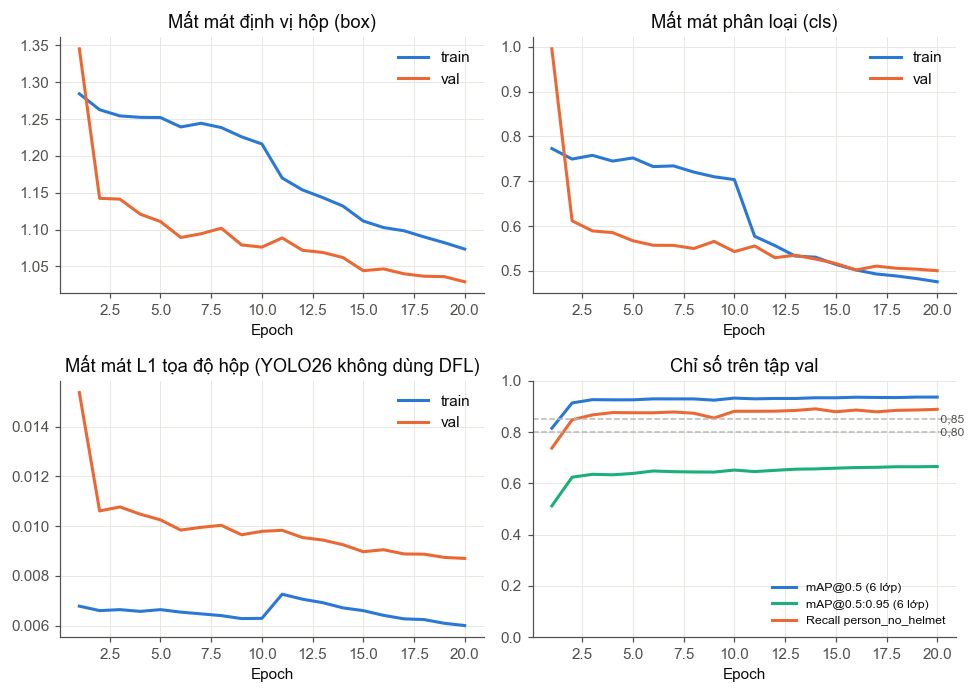

20 epoch, tổng thời gian huấn luyện 1.26 giờ


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

BLUE, ORANGE, AQUA, GRAY, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2", "#0b0b0b", "#52514e", "#e6e5e0"
fonts = {f.name for f in font_manager.fontManager.ttflist}
STYLE = {  # chỉ áp cho hình này, không ảnh hưởng hình Ultralytics vẽ ở các ô sau
    "font.family": next((f for f in ("Arial", "Liberation Sans") if f in fonts), "DejaVu Sans"), "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
}
TITLES = {"box_loss": "Mất mát định vị hộp (box)", "cls_loss": "Mất mát phân loại (cls)",
          "dfl_loss": "Mất mát phân phối biên (DFL)", "l1_loss": "Mất mát L1 tọa độ hộp (YOLO26 không dùng DFL)"}

res = pd.read_csv(run_dir / "results.csv").drop_duplicates("epoch", keep="last")  # epoch chạy lại khi resume
log = pd.read_csv(run_dir / "epoch_log.csv").drop_duplicates("epoch", keep="last")
loss_names = [c.split("/")[1] for c in res.columns if c.startswith("train/")]

with plt.rc_context(STYLE):
    rows = len(loss_names) // 2 + 1  # các ô mất mát + 1 ô chỉ số
    fig, axes = plt.subplots(rows, 2, figsize=(9, 3.2 * rows))
    axes = axes.ravel()
    for ax in axes[len(loss_names) + 1:]:
        ax.remove()
    for ax, name in zip(axes, loss_names):
        ax.plot(res["epoch"], res[f"train/{name}"], color=BLUE, lw=2, label="train")
        ax.plot(res["epoch"], res[f"val/{name}"], color=ORANGE, lw=2, label="val")
        ax.set(title=TITLES.get(name, name), xlabel="Epoch")
        ax.legend(frameon=False)
    ax = axes[len(loss_names)]
    ax.plot(res["epoch"], res["metrics/mAP50(B)"], color=BLUE, lw=2, label="mAP@0.5 (6 lớp)")
    ax.plot(res["epoch"], res["metrics/mAP50-95(B)"], color=AQUA, lw=2, label="mAP@0.5:0.95 (6 lớp)")
    ax.plot(log["epoch"], log["recall_priority"], color=ORANGE, lw=2, label=f"Recall {PRIORITY}")
    for y in (0.85, 0.80):
        ax.axhline(y, color=GRAY, lw=1, ls="--")
        ax.text(res["epoch"].max(), y, f" {y:.2f}".replace(".", ","), va="center", fontsize=8, color=INK2)
    ax.set(title="Chỉ số trên tập val", xlabel="Epoch", ylim=(0, 1))
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    fig.tight_layout()
    fig.savefig(run_dir / "fig_curves.png")
    plt.show()
print(f"{len(res)} epoch, tổng thời gian huấn luyện {log['seconds'].sum() / 3600:.2f} giờ")

## 6. Đánh giá `best.pt` trên val của từng nguồn

So với M3: val SHEL5K mAP@0.5 0,914, Open Images 0,925, SH17 0,934. Tập test SHEL5K, ba tập ngoài miền và 200 ảnh không người
đánh giá ở máy local sau khi tải kết quả về (cùng script như M3), không dùng ở đây.

In [19]:
import json

best = YOLO(run_dir / "weights" / "best.pt")
results = {}
for name, data in VAL_YAMLS.items():
    val = best.val(data=str(data), split="val", imgsz=IMGSZ, batch=BATCH, plots=name == "shel5k",
                   project=str(run_dir), name=f"val_best_{name}", exist_ok=True, verbose=False)
    per_class = pd.DataFrame(val.summary()).set_index("Class")
    print(f"== {name}: mAP@0.5 {val.box.map50:.3f}, mAP@0.5:0.95 {val.box.map:.3f}")
    display(per_class[["Instances", "Box-P", "Box-R", "mAP50", "mAP50-95"]].round(3))
    results[name] = {"val": val.results_dict, "per_class": val.summary(), "speed_ms": val.speed}

with open(run_dir / "val_metrics.json", "w") as f:
    json.dump({"run": RUN_NAME, "base": BASE_RUN, "epochs": EPOCHS, "imgsz": IMGSZ, "batch": BATCH, "hyp": HYP,
               "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
               "train_hours": round(log["seconds"].sum() / 3600, 2), **results},
              f, ensure_ascii=False, indent=2, default=lambda o: o.item())

Ultralytics 8.4.164 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3934.3±815.4 MB/s, size: 196.7 KB)
val: Scanning /content/SHEL5K_processed/labels/val... 751 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 751/751 1.4Kit/s 0.5s
val: New cache created: /content/SHEL5K_processed/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 3.4it/s 13.9s
                   all        751       9955      0.903      0.856      0.912      0.602
Speed: 1.9ms preprocess, 6.2ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/drive/MyDrive/DATN/runs/M3b_yolo26n_bg/val_best_shel5k
== shel5k: mAP@0.5 0.912, mAP@0.5:0.95 0.602


,Instances,Box-P,Box-R,mAP50,mAP50-95
Class,,,,,
helmet,2329,0.945,0.897,0.942,0.621
head,813,0.931,0.844,0.903,0.587
head_with_helmet,2079,0.906,0.922,0.952,0.667
person_with_helmet,2078,0.884,0.888,0.929,0.695
person_no_helmet,750,0.862,0.788,0.874,0.648
face,1906,0.891,0.795,0.869,0.393


Ultralytics 8.4.164 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3040.9±670.9 MB/s, size: 125.9 KB)
val: Scanning /content/M3_extra/openimages/labels/val... 64 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 64/64 2.0Kit/s 0.0s
val: New cache created: /content/M3_extra/openimages/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.5it/s 1.2s
                   all         64        214      0.896      0.885      0.934      0.663
Speed: 1.5ms preprocess, 7.4ms inference, 0.0ms loss, 1.8ms postprocess per image
== openimages: mAP@0.5 0.934, mAP@0.5:0.95 0.663


,Instances,Box-P,Box-R,mAP50,mAP50-95
Class,,,,,
head,71,0.777,0.738,0.829,0.431
person_no_helmet,71,0.967,0.972,0.988,0.838
face,72,0.942,0.944,0.985,0.719


Ultralytics 8.4.164 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2426.5±830.5 MB/s, size: 68.9 KB)
val: Scanning /content/M3_extra/sh17/labels/val... 1127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1127/1127 1.9Kit/s 0.6s
val: New cache created: /content/M3_extra/sh17/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 71/71 6.3it/s 11.3s
                   all       1127       5165        0.9      0.889      0.937      0.744
Speed: 1.2ms preprocess, 4.6ms inference, 0.0ms loss, 1.5ms postprocess per image
== sh17: mAP@0.5 0.937, mAP@0.5:0.95 0.744


,Instances,Box-P,Box-R,mAP50,mAP50-95
Class,,,,,
helmet,86,0.862,0.837,0.916,0.687
head,1711,0.975,0.939,0.969,0.753
head_with_helmet,86,0.840,0.858,0.896,0.746
person_with_helmet,86,0.803,0.854,0.908,0.759
person_no_helmet,1711,0.956,0.929,0.970,0.811
face,1485,0.961,0.918,0.962,0.706


## 7. Ma trận nhầm lẫn trên val SHEL5K (chuẩn hóa theo nhãn thật)

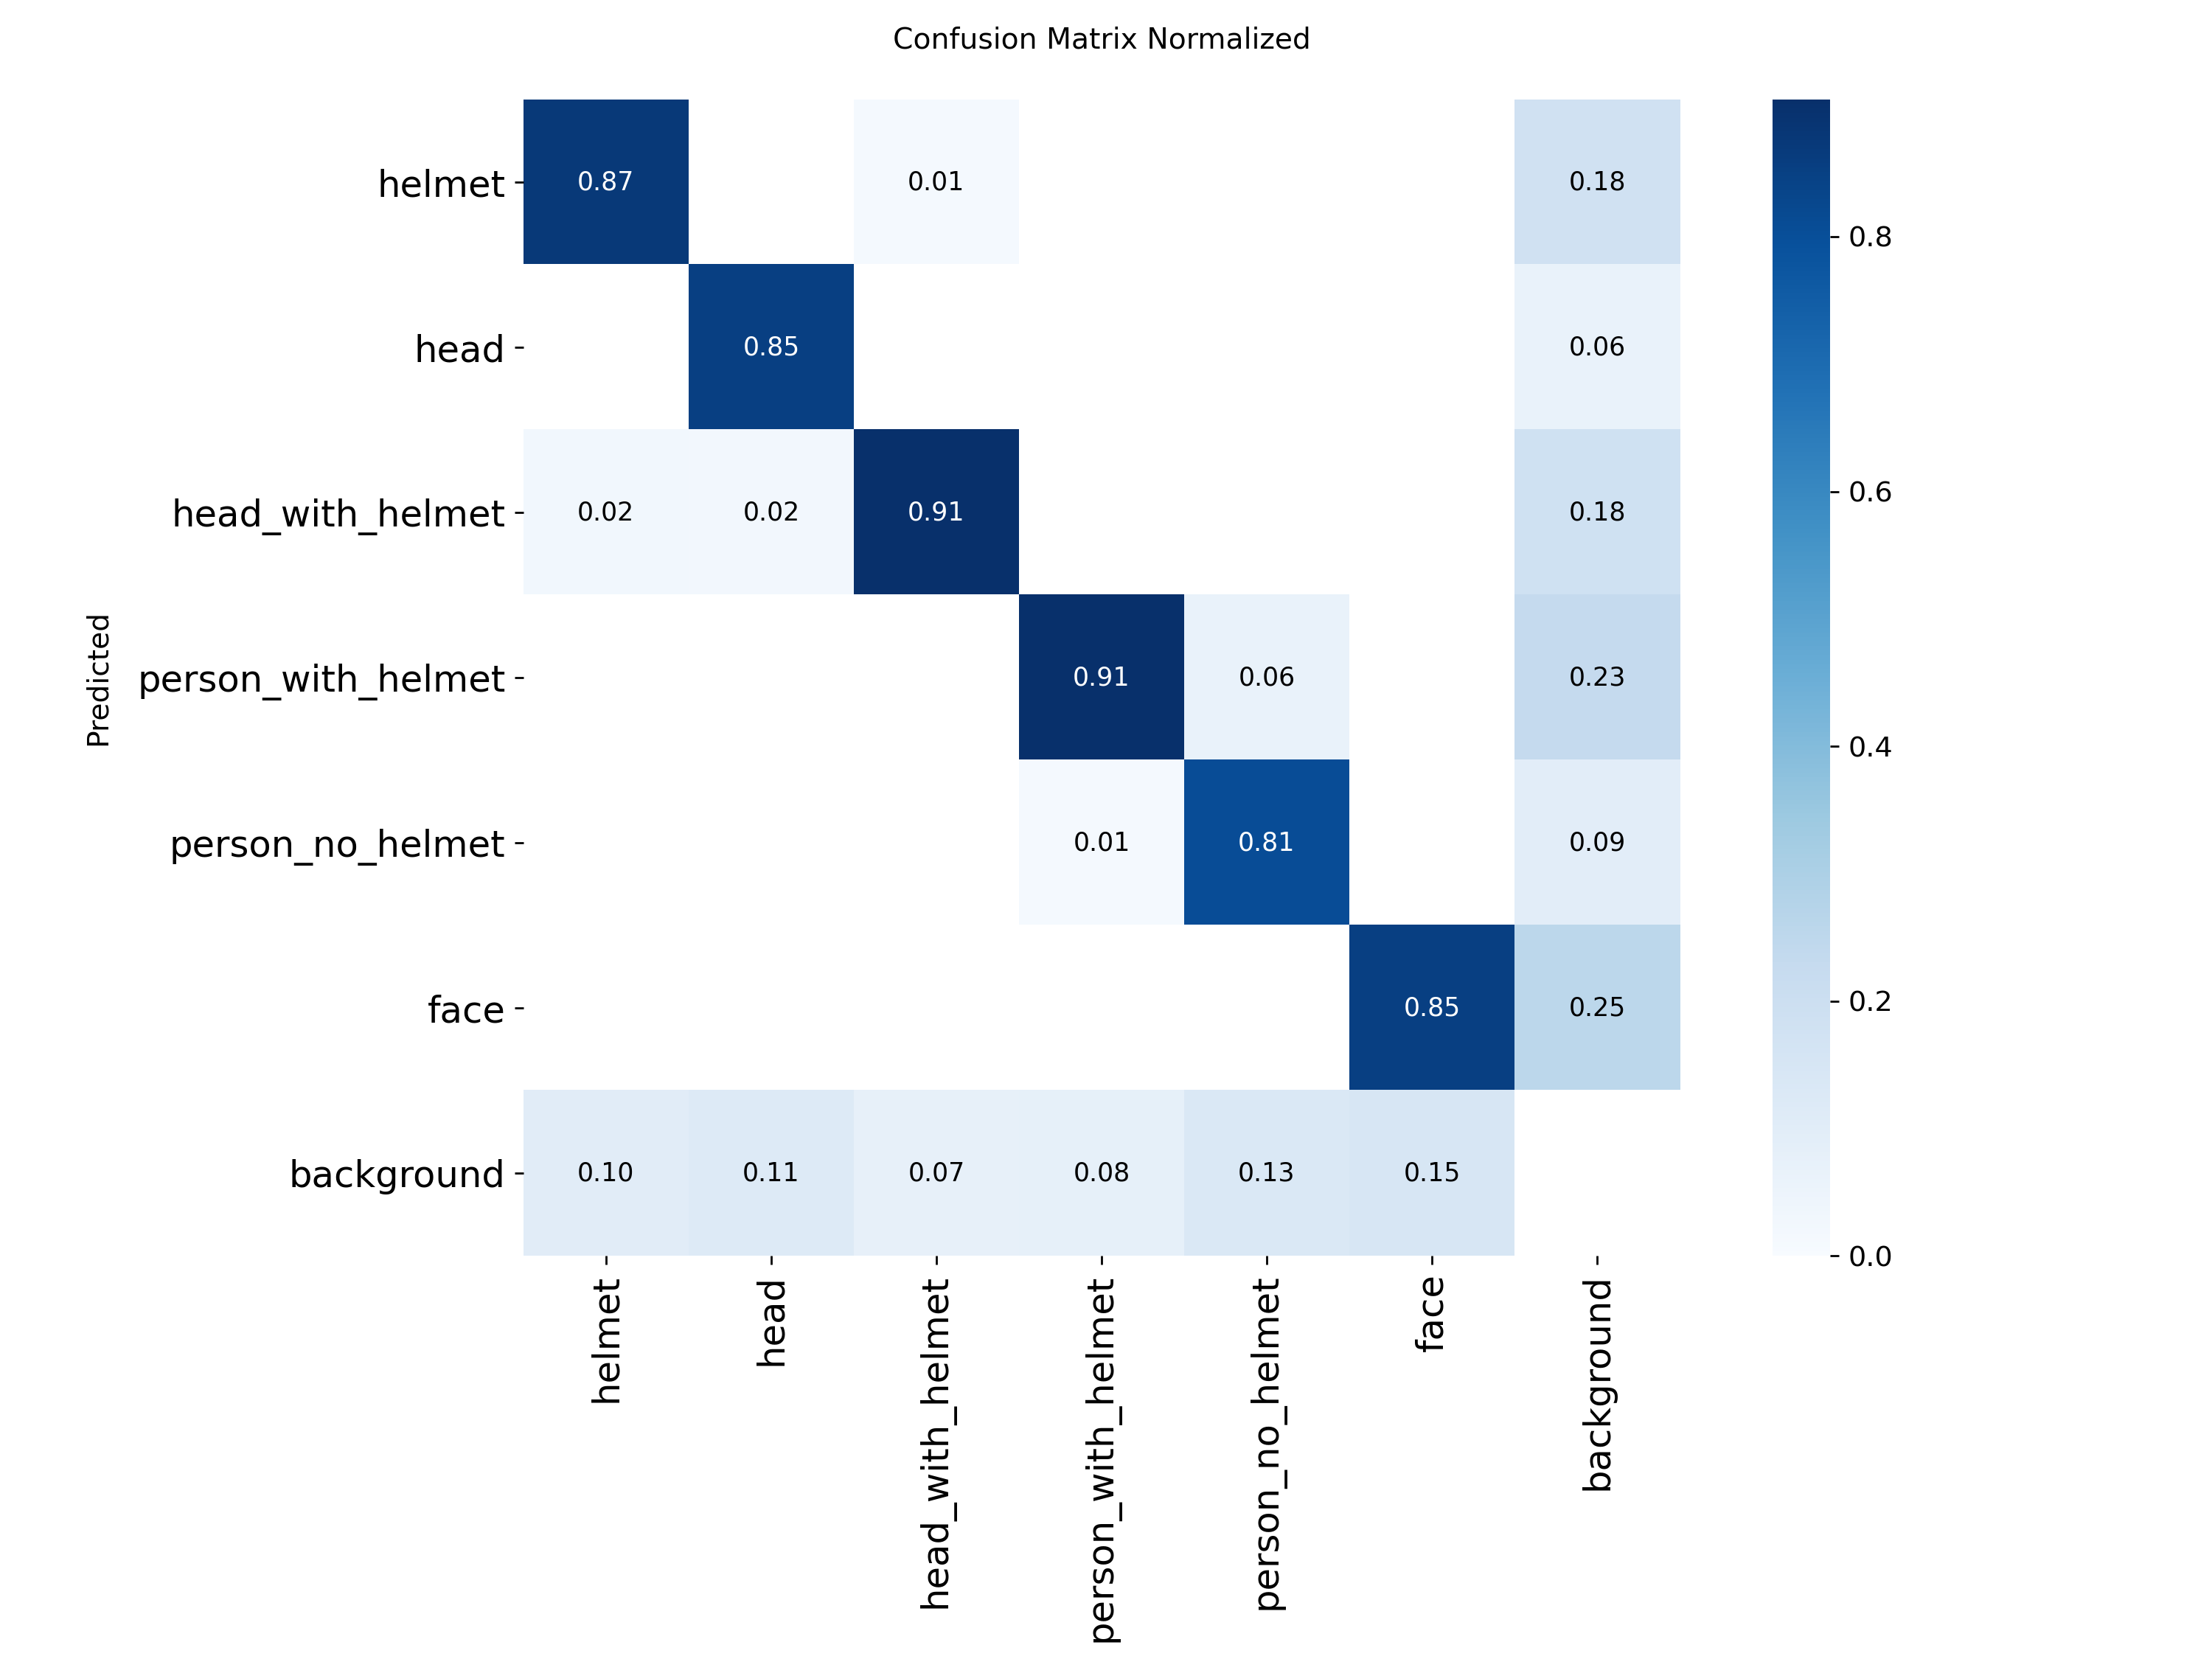

In [20]:
from IPython.display import Image

display(Image(filename=run_dir / "val_best_shel5k" / "confusion_matrix_normalized.png", width=700))

## 8. Đóng gói kết quả

Nén thư mục kết quả (bỏ `last.pt`, chỉ cần khi huấn luyện tiếp) thành `<RUN_NAME>_results.zip`, lưu ở `/content` và trên Drive.

In [21]:
import shutil

out = ROOT / f"{RUN_NAME}_results.zip"
with zipfile.ZipFile(out, "w") as z:
    for p in run_dir.rglob("*"):
        if p.is_file() and p.name != "last.pt":
            z.write(p, p.relative_to(PROJECT))
shutil.copy(out, PROJECT)
print(f"{out.name}: {out.stat().st_size / 1e6:.1f} MB, có ở {ROOT} và {PROJECT}")

M3b_yolo26n_bg_results.zip: 17.6 MB, có ở /content và /content/drive/MyDrive/DATN/runs
